# Indonesia Landslide Susceptibility Dataset

This notebook rebuilds the Indonesia/Cempaka dataset in the same overall style as the Kerala dataset-builder notebook:

- validates and preserves the original point inventories,
- keeps the supplied balanced landslide/non-landslide samples,
- samples all available conditioning-factor rasters,
- performs quality control and EDA,
- runs statistical checks,
- prepares train/test data using training-only preprocessing,
- saves a reproducibility manifest.

**Important:** `distriv` and `distroad` are retained in the initial Indonesia dataset and EDA.  
They are excluded **only when the modelling dataset is created**.

## 0. Packages

In [4]:
# Run once if your environment does not already contain these packages.
! pip install -U geopandas rasterio pyogrio shapely pyproj pandas numpy pyarrow matplotlib seaborn scikit-learn statsmodels scipy joblib

   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.9 MB ? eta -:--:--
   -------------------------------

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires pandas<3,>=1.4.0, but you have pandas 3.0.6 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\PCC\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [5]:
# 1 — Imports

from pathlib import Path
from datetime import datetime, timezone
import json
import math
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import mannwhitneyu, chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=UserWarning)

print("GeoPandas:", gpd.__version__)
print("Rasterio :", rasterio.__version__)

GeoPandas: 1.1.4
Rasterio : 1.4.4


In [6]:
# 2 — Configuration

# Notebook is expected to be inside /notebooks, matching the Kerala notebook layout.
PROJECT_ROOT = Path.cwd().resolve().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw" / "cempaka_indonesia"
PROCESSED_DIR = DATA_DIR / "processed"
FACTOR_DIR = RAW_DIR / "Landslide Controlling Factors"
POINT_DIR = RAW_DIR / "Landslide Point"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

TARGET_CRS = "EPSG:32749"
RANDOM_STATE = 42
TEST_SIZE = 0.20

# These two factors stay in the initial dataset and EDA.
# They are removed only when the modelling feature list is created.
MODEL_EXCLUDE_FACTORS = ["distriv", "distroad"]

print("Project root :", PROJECT_ROOT)
print("Indonesia data:", RAW_DIR)
print("Processed    :", PROCESSED_DIR)
print("Factors      :", FACTOR_DIR)
print("Raw exists   :", RAW_DIR.exists())

Project root : D:\PROJECTS\Landslide_prediction
Indonesia data: D:\PROJECTS\Landslide_prediction\data\raw\cempaka_indonesia
Processed    : D:\PROJECTS\Landslide_prediction\data\processed
Factors      : D:\PROJECTS\Landslide_prediction\data\raw\cempaka_indonesia\Landslide Controlling Factors
Raw exists   : True


## 1. Load and validate the original Indonesia inventories

In [7]:
# 3 — Direct source file paths

LANDSLIDE_PATH = POINT_DIR / "ls_center.gpkg"
NONLANDSLIDE_PATH = POINT_DIR / "non_ls.gpkg"

print("Landslide inventory    :", LANDSLIDE_PATH)
print("Non-landslide inventory:", NONLANDSLIDE_PATH)
print("Landslide exists       :", LANDSLIDE_PATH.exists())
print("Non-landslide exists   :", NONLANDSLIDE_PATH.exists())

if not LANDSLIDE_PATH.exists():
    raise FileNotFoundError(f"Landslide inventory not found: {LANDSLIDE_PATH}")

if not NONLANDSLIDE_PATH.exists():
    raise FileNotFoundError(f"Non-landslide inventory not found: {NONLANDSLIDE_PATH}")

if not FACTOR_DIR.exists():
    raise FileNotFoundError(f"Factor directory not found: {FACTOR_DIR}")

Landslide inventory    : D:\PROJECTS\Landslide_prediction\data\raw\cempaka_indonesia\Landslide Point\ls_center.gpkg
Non-landslide inventory: D:\PROJECTS\Landslide_prediction\data\raw\cempaka_indonesia\Landslide Point\non_ls.gpkg
Landslide exists       : True
Non-landslide exists   : True


In [8]:
# 4 — Load and validate both point inventories

landslides_raw = gpd.read_file(LANDSLIDE_PATH)
non_landslides_raw = gpd.read_file(NONLANDSLIDE_PATH)

def validate_point_inventory(gdf, name):
    print(f"\n{name}")
    print("-" * len(name))
    print("Shape:", gdf.shape)
    print("CRS  :", gdf.crs)
    print("Geometry types:")
    print(gdf.geom_type.value_counts())
    print("Columns:", gdf.columns.tolist())

    if gdf.crs is None:
        raise ValueError(f"{name} has no CRS.")

    if not gdf.geometry.notna().all():
        raise ValueError(f"{name} contains null geometries.")

    if not (gdf.geom_type == "Point").all():
        raise ValueError(f"{name} must contain only Point geometries.")

    print("Duplicate locations:", gdf.geometry.duplicated().sum())

validate_point_inventory(landslides_raw, "Landslide inventory")
validate_point_inventory(non_landslides_raw, "Non-landslide inventory")

if landslides_raw.crs != non_landslides_raw.crs:
    non_landslides_raw = non_landslides_raw.to_crs(landslides_raw.crs)
    print("\nReprojected non-landslide points to:", landslides_raw.crs)

if str(landslides_raw.crs) != TARGET_CRS:
    print(
        f"\nNOTE: source CRS is {landslides_raw.crs}; "
        f"modelling points will be reprojected to {TARGET_CRS}."
    )

print("\nCounts:")
print("Landslides    :", len(landslides_raw))
print("Non-landslides:", len(non_landslides_raw))


Landslide inventory
-------------------
Shape: (743, 4)
CRS  : EPSG:32749
Geometry types:
Point    743
Name: count, dtype: int64
Columns: ['lslpts', 'X', 'Y', 'geometry']
Duplicate locations: 0

Non-landslide inventory
-----------------------
Shape: (743, 4)
CRS  : EPSG:32749
Geometry types:
Point    743
Name: count, dtype: int64
Columns: ['lslpts', 'X', 'Y', 'geometry']
Duplicate locations: 0

Counts:
Landslides    : 743
Non-landslides: 743


## 2. Preserve the original Indonesia point inventories

In [9]:
# 5 — Save untouched master inventories before adding modelling fields

MASTER_LS_CSV = PROCESSED_DIR / "indonesia_landslide_master.csv"
MASTER_LS_GPKG = PROCESSED_DIR / "indonesia_landslide_master.gpkg"

MASTER_NLS_CSV = PROCESSED_DIR / "indonesia_nonlandslide_master.csv"
MASTER_NLS_GPKG = PROCESSED_DIR / "indonesia_nonlandslide_master.gpkg"

def save_master_inventory(gdf, csv_path, gpkg_path, layer):
    csv_df = gdf.copy()
    csv_df["geometry"] = csv_df.geometry.to_wkt()
    csv_df.to_csv(csv_path, index=False, encoding="utf-8-sig")

    if not gpkg_path.exists():
        gdf.to_file(gpkg_path, layer=layer, driver="GPKG")

save_master_inventory(
    landslides_raw,
    MASTER_LS_CSV,
    MASTER_LS_GPKG,
    "landslides"
)

save_master_inventory(
    non_landslides_raw,
    MASTER_NLS_CSV,
    MASTER_NLS_GPKG,
    "non_landslides"
)

print("Saved landslide master    :", MASTER_LS_CSV)
print("Saved non-landslide master:", MASTER_NLS_CSV)

Saved landslide master    : D:\PROJECTS\Landslide_prediction\data\processed\indonesia_landslide_master.csv
Saved non-landslide master: D:\PROJECTS\Landslide_prediction\data\processed\indonesia_nonlandslide_master.csv


## 3. Prepare the balanced modelling points

In [10]:
# 6 — Standardize point attributes

landslides = landslides_raw.to_crs(TARGET_CRS).copy()
non_landslides = non_landslides_raw.to_crs(TARGET_CRS).copy()

landslides["lslpts"] = "TRUE"
landslides["label"] = 1
landslides["source"] = "Indonesia_Cempaka_Landslide_2017"
landslides["X"] = landslides.geometry.x
landslides["Y"] = landslides.geometry.y

non_landslides["lslpts"] = "FALSE"
non_landslides["label"] = 0
non_landslides["source"] = "Indonesia_Cempaka_NonLandslide_2017"
non_landslides["X"] = non_landslides.geometry.x
non_landslides["Y"] = non_landslides.geometry.y

print("Landslide samples    :", len(landslides))
print("Non-landslide samples:", len(non_landslides))

if len(landslides) != len(non_landslides):
    raise ValueError(
        "The supplied Indonesia inventories are not balanced. "
        "This notebook intentionally preserves the supplied samples rather than generating replacements."
    )

Landslide samples    : 743
Non-landslide samples: 743


In [11]:
# 7 — Build balanced modelling-point table

BASE_COLUMNS = ["lslpts", "X", "Y", "geometry", "label", "source"]

combined = pd.concat(
    [
        landslides[BASE_COLUMNS],
        non_landslides[BASE_COLUMNS]
    ],
    ignore_index=True
)

combined = gpd.GeoDataFrame(
    combined,
    geometry="geometry",
    crs=TARGET_CRS
)

print(combined["label"].value_counts())
print("Total:", len(combined))
print("CRS  :", combined.crs)

if combined["label"].value_counts().nunique() != 1:
    raise ValueError("Classes are not balanced.")

label
1    743
0    743
Name: count, dtype: int64
Total: 1486
CRS  : EPSG:32749


## 4. Inspect the supplied conditioning-factor rasters

In [12]:
# 8 — Find and inspect the supplied raster factors

factor_files = sorted(FACTOR_DIR.glob("map_*.tif"))

if not factor_files:
    raise FileNotFoundError(f"No map_*.tif rasters found in {FACTOR_DIR}")

print(f"{len(factor_files)} factor rasters found:")
for path in factor_files:
    print(" -", path.name)

EXPECTED_FACTORS = {
    "aspect",
    "distriv",
    "distroad",
    "elev",
    "geologi",
    "landuse",
    "planc",
    "profc",
    "slope",
    "spi",
    "twi",
}

available_factor_names = {
    p.stem.replace("map_", "")
    for p in factor_files
}

missing_expected = sorted(EXPECTED_FACTORS - available_factor_names)
extra_factors = sorted(available_factor_names - EXPECTED_FACTORS)

print("\nMissing expected factors:", missing_expected)
print("Additional factors      :", extra_factors)

if missing_expected:
    raise FileNotFoundError(
        "Expected Indonesia factor raster(s) missing: "
        + ", ".join(missing_expected)
    )

11 factor rasters found:
 - map_aspect.tif
 - map_distriv.tif
 - map_distroad.tif
 - map_elev.tif
 - map_geologi.tif
 - map_landuse.tif
 - map_planc.tif
 - map_profc.tif
 - map_slope.tif
 - map_spi.tif
 - map_twi.tif

Missing expected factors: []
Additional factors      : []


In [13]:
# 9 — Raster metadata check

raster_metadata = []

for path in factor_files:
    with rasterio.open(path) as src:
        raster_metadata.append(
            {
                "factor": path.stem.replace("map_", ""),
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "resolution_x": abs(src.res[0]),
                "resolution_y": abs(src.res[1]),
                "nodata": src.nodata,
                "dtype": src.dtypes[0],
            }
        )

raster_metadata_df = pd.DataFrame(raster_metadata).sort_values("factor")
display(raster_metadata_df)

,factor,crs,width,height,resolution_x,resolution_y,nodata,dtype
0,aspect,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
1,distriv,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
2,distroad,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
3,elev,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
4,geologi,EPSG:32749,5815,4051,10.0,10.0,-1.280000e+02,int8
5,landuse,EPSG:32749,5815,4051,10.0,10.0,1.500000e+01,uint8
6,planc,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
7,profc,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
8,slope,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32
9,spi,EPSG:32749,5815,4051,10.0,10.0,-3.402823e+38,float32


## 5. Sample every supplied raster factor at all points

In [14]:
# 10 — Robust raster sampling helper

def sample_raster_at_points(raster_path, points_gdf, band=1):
    raster_path = Path(raster_path)

    with rasterio.open(raster_path) as src:
        pts = (
            points_gdf.to_crs(src.crs)
            if points_gdf.crs != src.crs
            else points_gdf
        )

        coords = [(geom.x, geom.y) for geom in pts.geometry]

        values = np.array(
            [value[band - 1] for value in src.sample(coords)],
            dtype="float64"
        )

        if src.nodata is not None:
            if np.isnan(src.nodata):
                values[np.isnan(values)] = np.nan
            else:
                values[values == src.nodata] = np.nan

        values[~np.isfinite(values)] = np.nan

    return values

In [15]:
# 11 — Define Indonesia factor types

# Keep distance-to-river and distance-to-road here.
# They are part of the initial dataset and EDA.
continuous_factor_columns = [
    "aspect",
    "distriv",
    "distroad",
    "elev",
    "planc",
    "profc",
    "slope",
    "spi",
    "twi",
]

categorical_factor_columns = [
    "geologi",
    "landuse",
]

dataset_factor_columns = (
    continuous_factor_columns
    + categorical_factor_columns
)

print("Continuous dataset factors :", continuous_factor_columns)
print("Categorical dataset factors:", categorical_factor_columns)
print("All dataset factors        :", dataset_factor_columns)

Continuous dataset factors : ['aspect', 'distriv', 'distroad', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi']
Categorical dataset factors: ['geologi', 'landuse']
All dataset factors        : ['aspect', 'distriv', 'distroad', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']


In [16]:
# 12 — Sample every factor

factor_paths = {
    path.stem.replace("map_", ""): path
    for path in factor_files
}

for factor in dataset_factor_columns:
    path = factor_paths[factor]

    combined[factor] = sample_raster_at_points(
        path,
        combined
    )

    valid = combined[factor].notna().sum()
    missing = combined[factor].isna().sum()

    print(
        f"{factor:10s}: "
        f"{valid:,}/{len(combined):,} valid | "
        f"{missing:,} missing"
    )

# Preserve categorical codes as integer-like nullable values where possible.
for factor in categorical_factor_columns:
    combined[factor] = combined[factor].round().astype("Int64")

aspect    : 1,486/1,486 valid | 0 missing
distriv   : 1,486/1,486 valid | 0 missing
distroad  : 1,486/1,486 valid | 0 missing
elev      : 1,486/1,486 valid | 0 missing
planc     : 1,486/1,486 valid | 0 missing
profc     : 1,486/1,486 valid | 0 missing
slope     : 1,486/1,486 valid | 0 missing
spi       : 1,486/1,486 valid | 0 missing
twi       : 1,486/1,486 valid | 0 missing
geologi   : 1,485/1,486 valid | 1 missing
landuse   : 1,486/1,486 valid | 0 missing


In [17]:
# 13 — Quick factor check

print("Continuous factor statistics:")
display(
    combined[continuous_factor_columns]
    .describe()
    .T
)

for factor in categorical_factor_columns:
    print(f"\n{factor.upper()} class counts")
    display(
        combined[factor]
        .value_counts(dropna=False)
        .sort_index()
        .to_frame("count")
    )

Continuous factor statistics:


,count,mean,std,min,25%,50%,75%,max
aspect,1486.0,171.564468,104.522297,0.000,81.674999,161.150002,260.150009,360.000000
distriv,1486.0,228.709085,497.703526,0.100,40.000000,102.000000,218.399994,5230.700195
distroad,1486.0,186.885666,201.092131,0.100,50.000000,120.800003,260.799988,2021.199951
elev,1486.0,422.172880,268.424318,-5.400,209.550003,374.949997,604.100021,1163.099976
planc,1486.0,-0.001283,0.030670,-0.249,-0.011000,-0.001000,0.009000,0.211000
profc,1486.0,-0.000663,0.004109,-0.025,-0.003000,-0.001000,0.002000,0.018000
slope,1486.0,18.905047,8.970053,0.600,12.025000,18.900000,25.675001,46.000000
spi,1486.0,0.503583,0.976920,-5.956,0.150750,0.532000,1.030250,4.079000
twi,1486.0,5.861783,2.269260,3.060,4.580000,5.220000,6.210000,22.370001



GEOLOGI class counts


,count
geologi,
2,50
7,374
8,217
12,10
13,4
16,44
20,37
26,114
27,51



LANDUSE class counts


,count
landuse,
1,1
2,7
3,385
4,13
5,29
6,266
8,169
10,92
11,198


## 6. Quality control and save the full Indonesia dataset

In [18]:
# 14 — Quality-control report

REPORT_COLUMNS = BASE_COLUMNS + dataset_factor_columns

print("Rows:", len(combined))

print("\nClass balance:")
print(combined["label"].value_counts())

print("\nMissing values (%):")
print(
    (combined[REPORT_COLUMNS].isna().mean() * 100)
    .round(2)
)

print(
    "\nDuplicate modelling geometries:",
    combined.geometry.duplicated().sum()
)

factor_missing = combined[dataset_factor_columns].isna().sum()

if factor_missing.any():
    print("\nWARNING — missing factor values:")
    print(factor_missing[factor_missing > 0])
else:
    print("\nAll selected factor values are complete.")

print("\nInitial dataset factors:")
for factor in dataset_factor_columns:
    print(" -", factor)

Rows: 1486

Class balance:
label
1    743
0    743
Name: count, dtype: int64

Missing values (%):
lslpts      0.00
X           0.00
Y           0.00
geometry    0.00
label       0.00
source      0.00
aspect      0.00
distriv     0.00
distroad    0.00
elev        0.00
planc       0.00
profc       0.00
slope       0.00
spi         0.00
twi         0.00
geologi     0.07
landuse     0.00
dtype: float64

Duplicate modelling geometries: 0

WARNING — missing factor values:
geologi    1
dtype: int64

Initial dataset factors:
 - aspect
 - distriv
 - distroad
 - elev
 - planc
 - profc
 - slope
 - spi
 - twi
 - geologi
 - landuse


In [19]:
# 15 — Save the full Indonesia susceptibility dataset
# IMPORTANT: distriv and distroad are still included here.

FINAL_COLUMNS = BASE_COLUMNS + dataset_factor_columns

def save_geocsv(gdf, path, columns):
    out = gdf[columns].copy()
    out["geometry"] = out.geometry.to_wkt()
    out.to_csv(path, index=False, encoding="utf-8-sig")
    return path

FINAL_CSV = PROCESSED_DIR / "training_table_indonesia_extended.csv"
FINAL_PARQUET = PROCESSED_DIR / "training_table_indonesia_extended.parquet"

save_geocsv(combined, FINAL_CSV, FINAL_COLUMNS)
combined[FINAL_COLUMNS].to_parquet(FINAL_PARQUET, index=False)

print("Saved CSV    :", FINAL_CSV)
print("Saved Parquet:", FINAL_PARQUET)
print("Shape        :", combined[FINAL_COLUMNS].shape)
print("Factors      :", dataset_factor_columns)

assert "distriv" in combined[FINAL_COLUMNS].columns
assert "distroad" in combined[FINAL_COLUMNS].columns

print("\nConfirmed: distriv and distroad are retained in the saved initial dataset.")

Saved CSV    : D:\PROJECTS\Landslide_prediction\data\processed\training_table_indonesia_extended.csv
Saved Parquet: D:\PROJECTS\Landslide_prediction\data\processed\training_table_indonesia_extended.parquet
Shape        : (1486, 17)
Factors      : ['aspect', 'distriv', 'distroad', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']

Confirmed: distriv and distroad are retained in the saved initial dataset.


In [20]:
# 16 — Reproducibility manifest

factor_sources = {
    factor: str(factor_paths[factor])
    for factor in dataset_factor_columns
}

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "source_data_dir": str(RAW_DIR),
    "source_landslide_inventory": str(LANDSLIDE_PATH),
    "source_nonlandslide_inventory": str(NONLANDSLIDE_PATH),
    "landslide_count": int((combined["label"] == 1).sum()),
    "nonlandslide_count": int((combined["label"] == 0).sum()),
    "total_samples": int(len(combined)),
    "target_crs": TARGET_CRS,
    "random_state": RANDOM_STATE,
    "dataset_continuous_factors": continuous_factor_columns,
    "dataset_categorical_factors": categorical_factor_columns,
    "dataset_factors": dataset_factor_columns,
    "factor_sources": factor_sources,
    "model_excluded_factors": MODEL_EXCLUDE_FACTORS,
    "model_exclusion_stage": "Preprocessing for modelling only",
    "model_exclusion_note": (
        "distriv and distroad are intentionally retained in the raw/extended "
        "Indonesia dataset and EDA, then removed only from the modelling feature list."
    ),
}

MANIFEST_PATH = PROCESSED_DIR / "indonesia_dataset_manifest.json"

MANIFEST_PATH.write_text(
    json.dumps(manifest, indent=2),
    encoding="utf-8"
)

print(json.dumps(manifest, indent=2))
print("\nManifest saved:", MANIFEST_PATH)

{
  "created_utc": "2026-09-25T13:10:18.898057+00:00",
  "source_data_dir": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\cempaka_indonesia",
  "source_landslide_inventory": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\cempaka_indonesia\\Landslide Point\\ls_center.gpkg",
  "source_nonlandslide_inventory": "D:\\PROJECTS\\Landslide_prediction\\data\\raw\\cempaka_indonesia\\Landslide Point\\non_ls.gpkg",
  "landslide_count": 743,
  "nonlandslide_count": 743,
  "total_samples": 1486,
  "target_crs": "EPSG:32749",
  "random_state": 42,
  "dataset_continuous_factors": [
    "aspect",
    "distriv",
    "distroad",
    "elev",
    "planc",
    "profc",
    "slope",
    "spi",
    "twi"
  ],
  "dataset_categorical_factors": [
    "geologi",
    "landuse"
  ],
  "dataset_factors": [
    "aspect",
    "distriv",
    "distroad",
    "elev",
    "planc",
    "profc",
    "slope",
    "spi",
    "twi",
    "geologi",
    "landuse"
  ],
  "factor_sources": {
    "aspect": "D:\\PROJECTS\\Landsli

## 7. Exploratory data analysis (EDA)

In [21]:
# 17 — Load the saved full dataset for EDA

eda_df = pd.read_csv(FINAL_CSV)

print("Shape:", eda_df.shape)

print("\nClass balance:")
print(eda_df["label"].value_counts())

print("\nMissing factors (%):")
print(
    (eda_df[dataset_factor_columns].isna().mean() * 100)
    .round(2)
)

print("\nEDA includes distriv:", "distriv" in eda_df.columns)
print("EDA includes distroad:", "distroad" in eda_df.columns)

eda_df.head()

Shape: (1486, 17)

Class balance:
label
1    743
0    743
Name: count, dtype: int64

Missing factors (%):
aspect      0.00
distriv     0.00
distroad    0.00
elev        0.00
planc       0.00
profc       0.00
slope       0.00
spi         0.00
twi         0.00
geologi     0.07
landuse     0.00
dtype: float64

EDA includes distriv: True
EDA includes distroad: True


,lslpts,X,Y,geometry,label,source,aspect,distriv,distroad,elev,planc,profc,slope,spi,twi,geologi,landuse
0,True,509435.847792,9.093568e+06,POINT (509435.847792 9093568.4712),1,Indonesia_Cempaka_Landslide_2017,171.100006,679.000000,10.000000,3.900000,-0.113,-0.002,2.300000,0.074,10.37,2.0,10
1,True,514069.366439,9.093404e+06,POINT (514069.366439 9093403.96027),1,Indonesia_Cempaka_Landslide_2017,277.600006,739.299988,28.299999,29.500000,0.011,-0.001,21.000000,0.850,4.81,2.0,8
2,True,514979.679513,9.094294e+06,POINT (514979.679513 9094293.96908),1,Indonesia_Cempaka_Landslide_2017,345.100006,702.099976,222.000000,135.199997,0.006,0.000,25.500000,0.330,4.84,32.0,3
3,True,518012.406006,9.088957e+06,POINT (518012.406006 9088957.1239),1,Indonesia_Cempaka_Landslide_2017,356.299988,376.399994,557.299988,198.899994,-0.071,-0.005,9.600000,0.642,9.49,32.0,6
4,True,518427.827438,9.089537e+06,POINT (518427.827438 9089536.99478),1,Indonesia_Cempaka_Landslide_2017,250.899994,70.000000,493.399994,155.399994,0.024,-0.001,31.200001,-4.206,3.88,32.0,6


In [22]:
# 18 — Descriptive statistics for continuous factors by class

display(
    eda_df
    .groupby("label")[continuous_factor_columns]
    .describe()
    .T
)

label                  0           1
aspect count  743.000000  743.000000
       mean   190.684926  152.444011
       std     97.647797  107.690684
       min      2.200000    0.000000
       25%    111.450001   64.150000
...                  ...         ...
twi    min      3.220000    3.060000
       25%      4.580000    4.585000
       50%      5.300000    5.160000
       75%      6.580000    5.930000
       max     22.370001   19.820000

[72 rows x 2 columns]

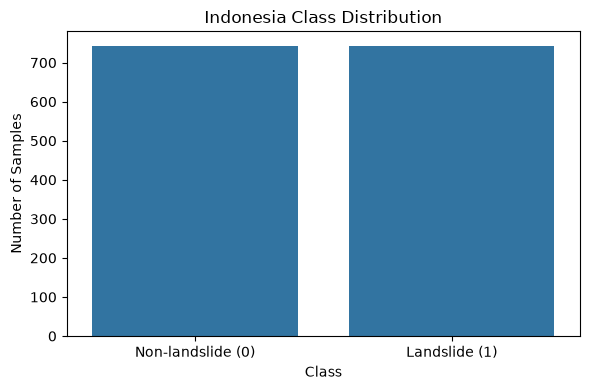

In [23]:
# 19 — Class balance visualization

plt.figure(figsize=(6, 4))

sns.countplot(
    data=eda_df,
    x="label"
)

plt.title("Indonesia Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.xticks(
    [0, 1],
    [
        "Non-landslide (0)",
        "Landslide (1)"
    ]
)

plt.tight_layout()
plt.show()

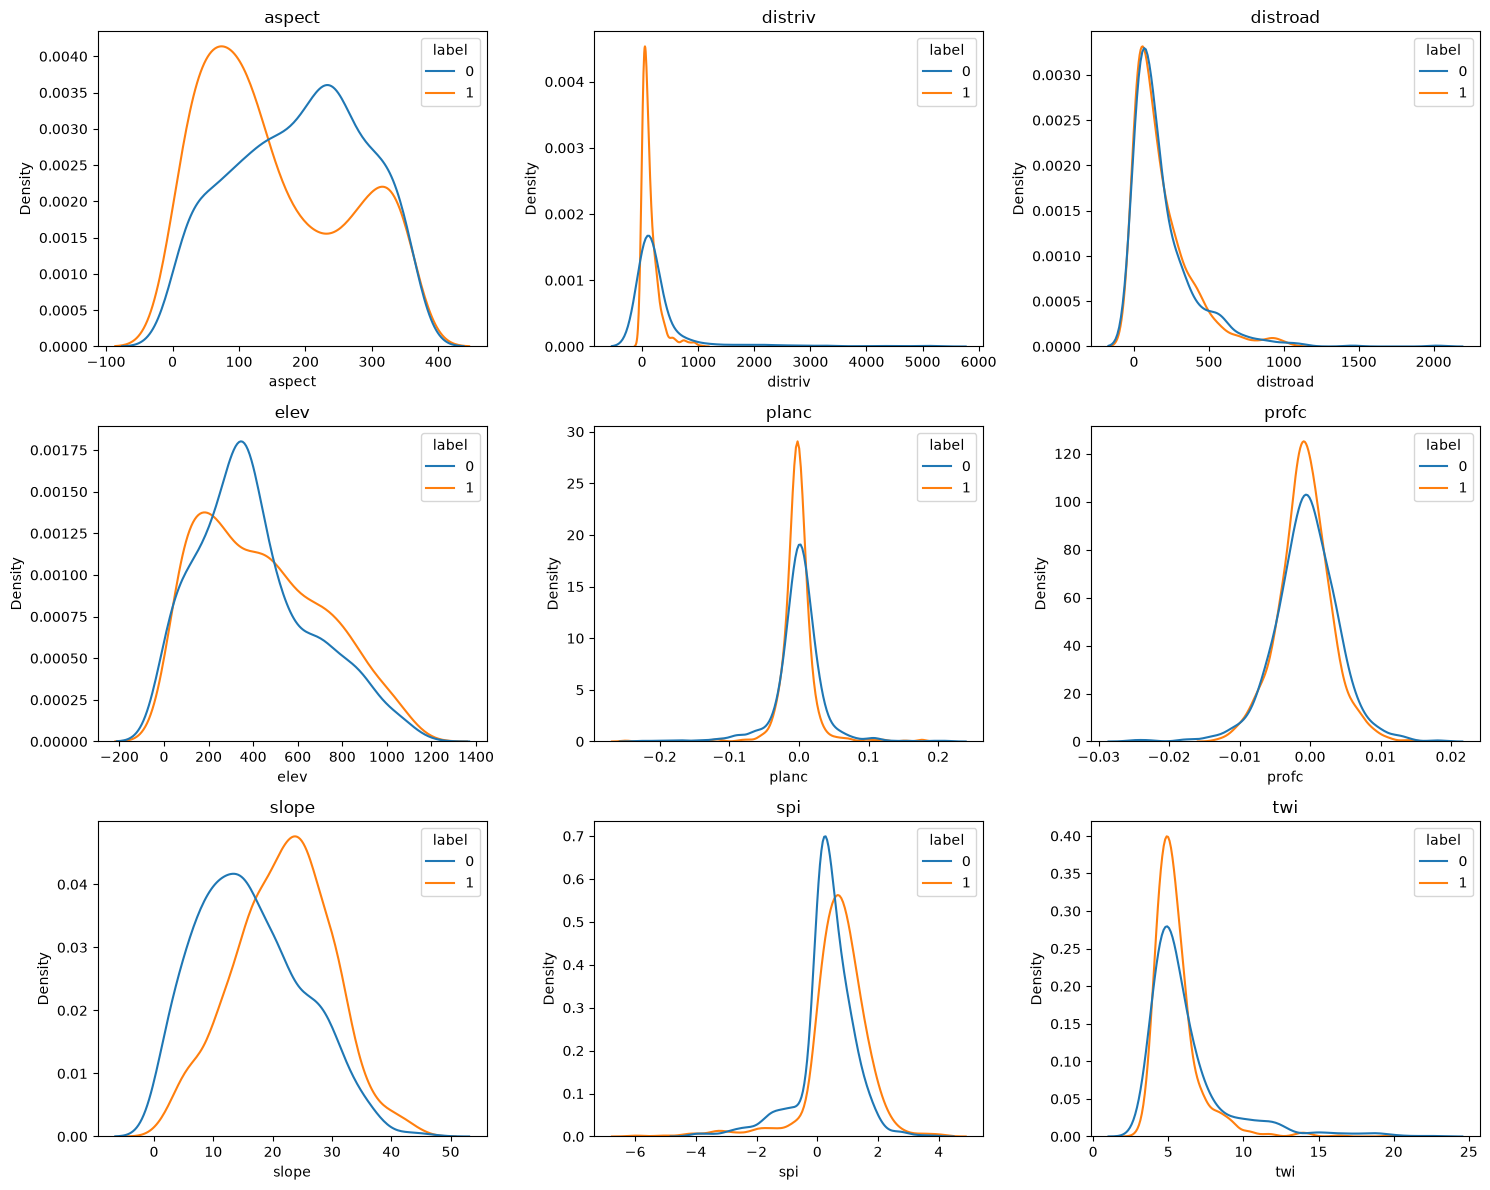

In [24]:
# 20 — Continuous-factor distributions by class

n = len(continuous_factor_columns)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, 4 * nrows)
)

axes = np.atleast_1d(axes).flatten()

for i, col in enumerate(continuous_factor_columns):
    sns.kdeplot(
        data=eda_df,
        x=col,
        hue="label",
        common_norm=False,
        ax=axes[i]
    )
    axes[i].set_title(col)

for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

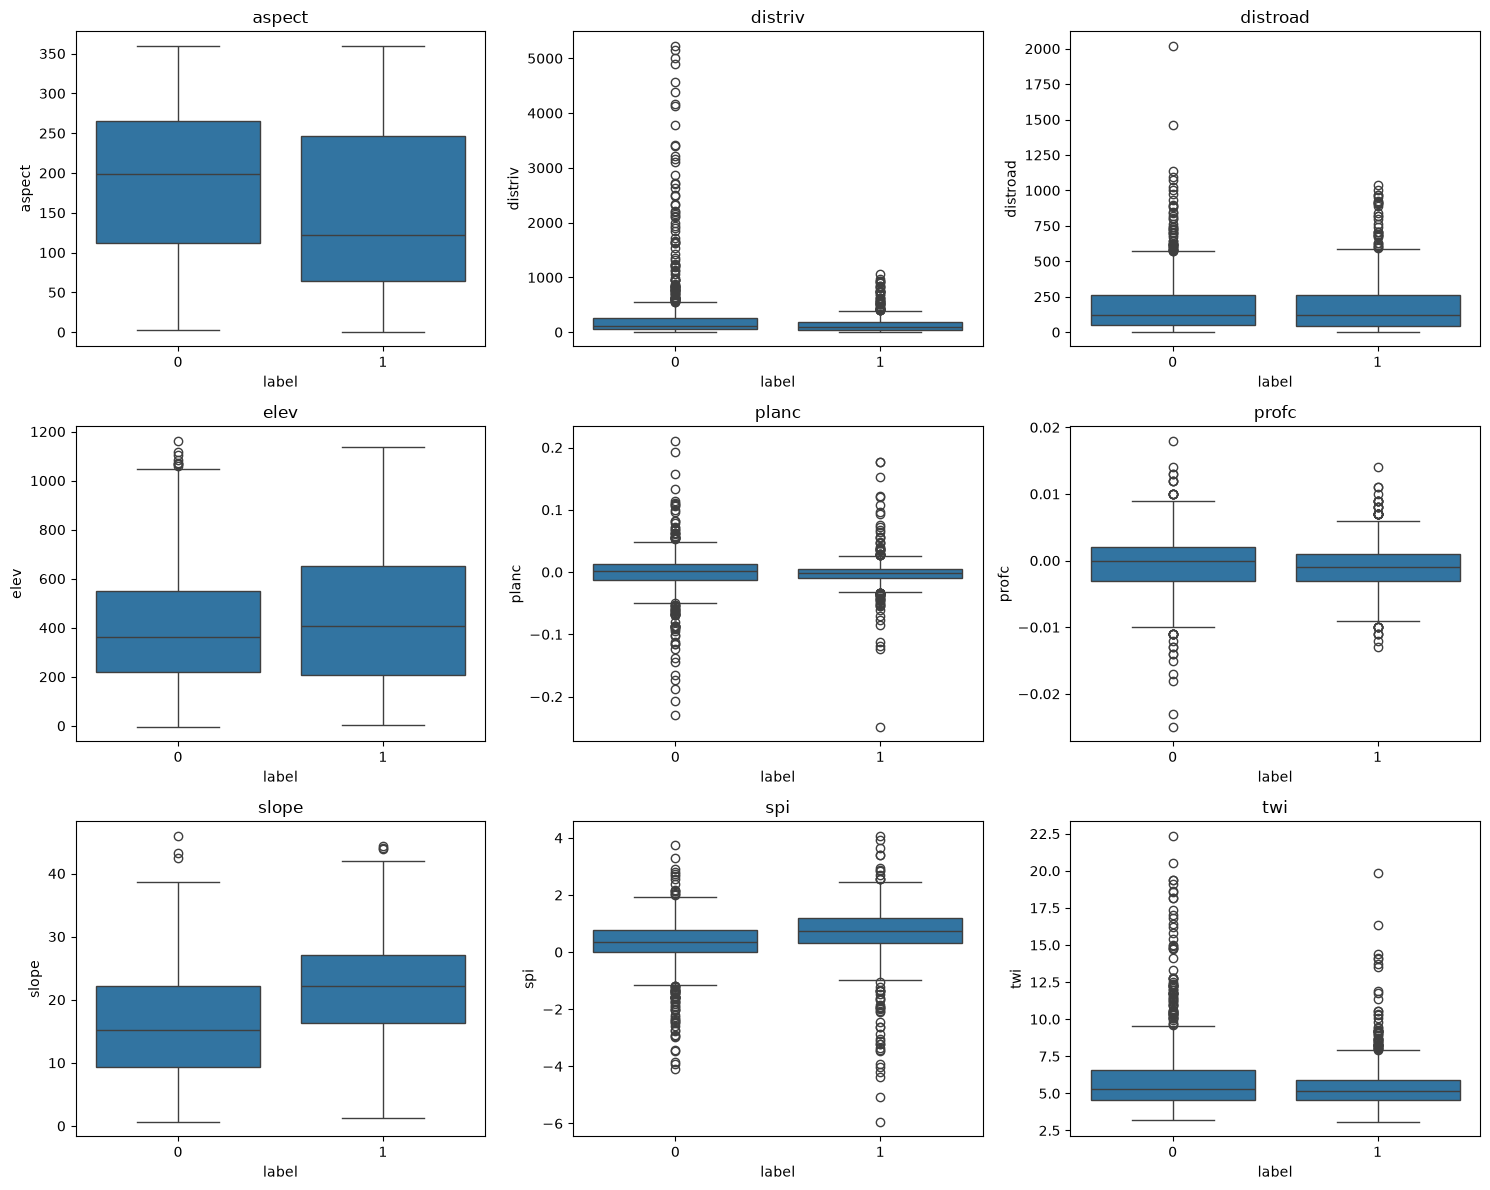

In [25]:
# 21 — Continuous-factor boxplots by class

n = len(continuous_factor_columns)
ncols = 3
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(15, 4 * nrows)
)

axes = np.atleast_1d(axes).flatten()

for i, col in enumerate(continuous_factor_columns):
    sns.boxplot(
        data=eda_df,
        x="label",
        y=col,
        ax=axes[i]
    )
    axes[i].set_title(col)

for j in range(n, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

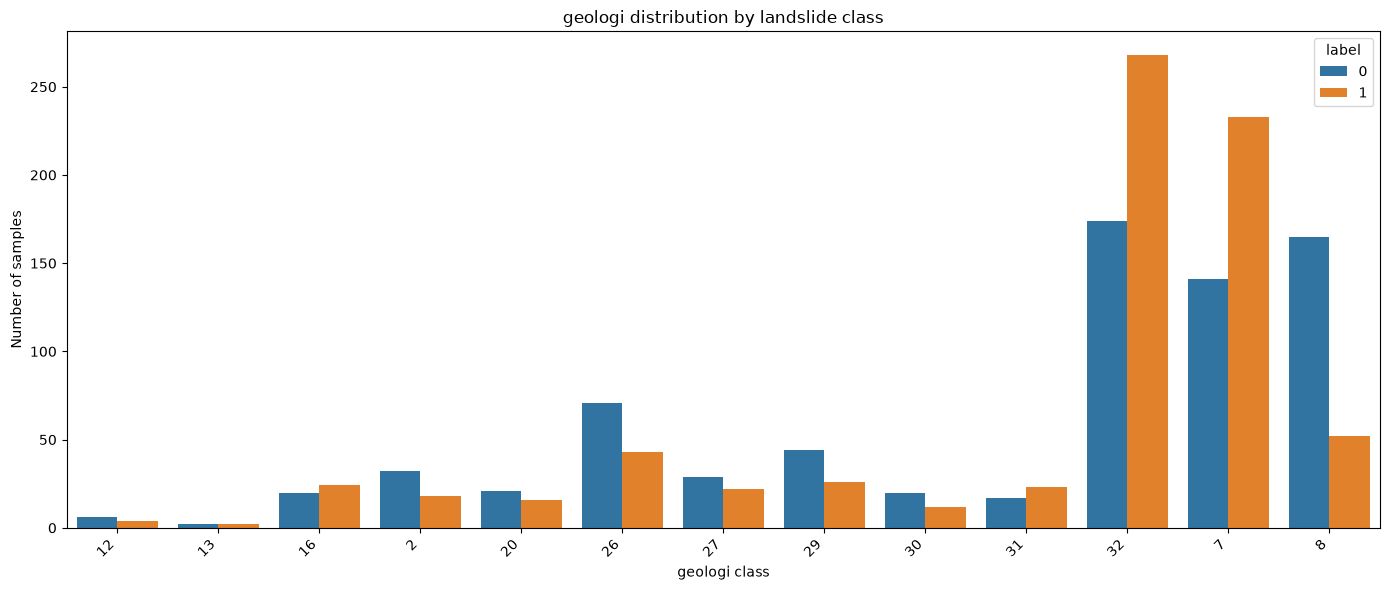

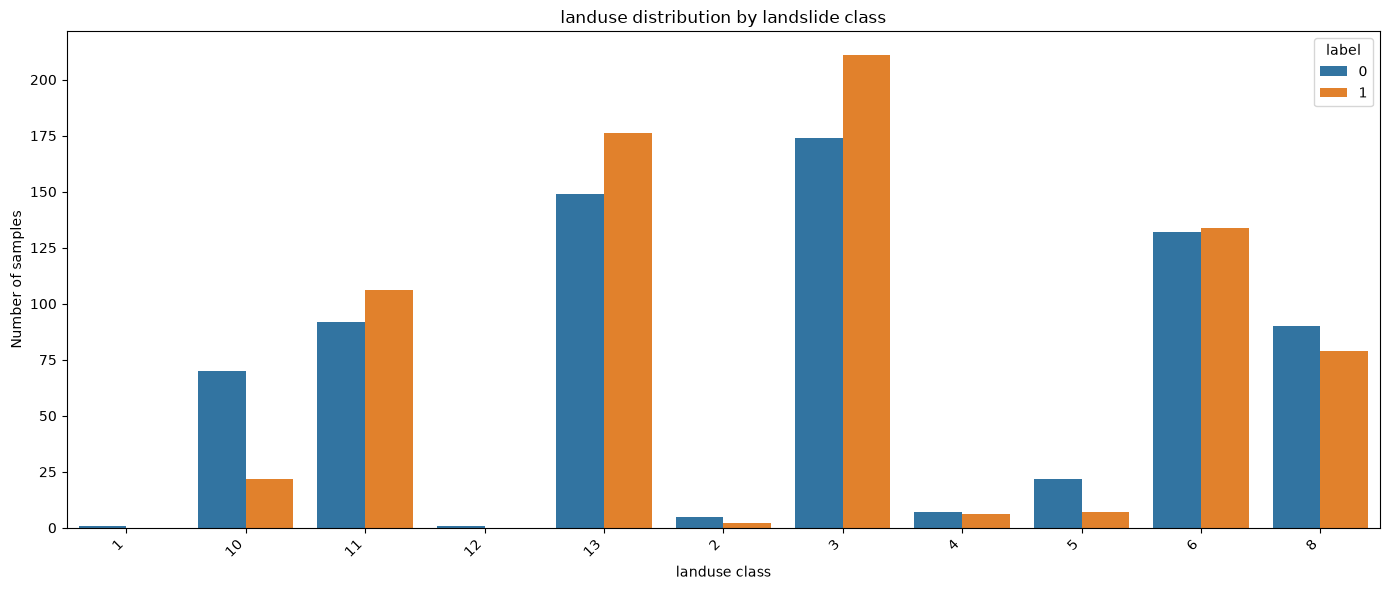

In [26]:
# 22 — Categorical factor distributions by class

for col in categorical_factor_columns:
    plot_df = eda_df[[col, "label"]].dropna().copy()
    plot_df["category_label"] = plot_df[col].astype("Int64").astype(str)

    counts = (
        plot_df
        .groupby(["category_label", "label"])
        .size()
        .reset_index(name="count")
    )

    plt.figure(figsize=(14, 6))

    sns.barplot(
        data=counts,
        x="category_label",
        y="count",
        hue="label"
    )

    plt.title(f"{col} distribution by landslide class")
    plt.xlabel(f"{col} class")
    plt.ylabel("Number of samples")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

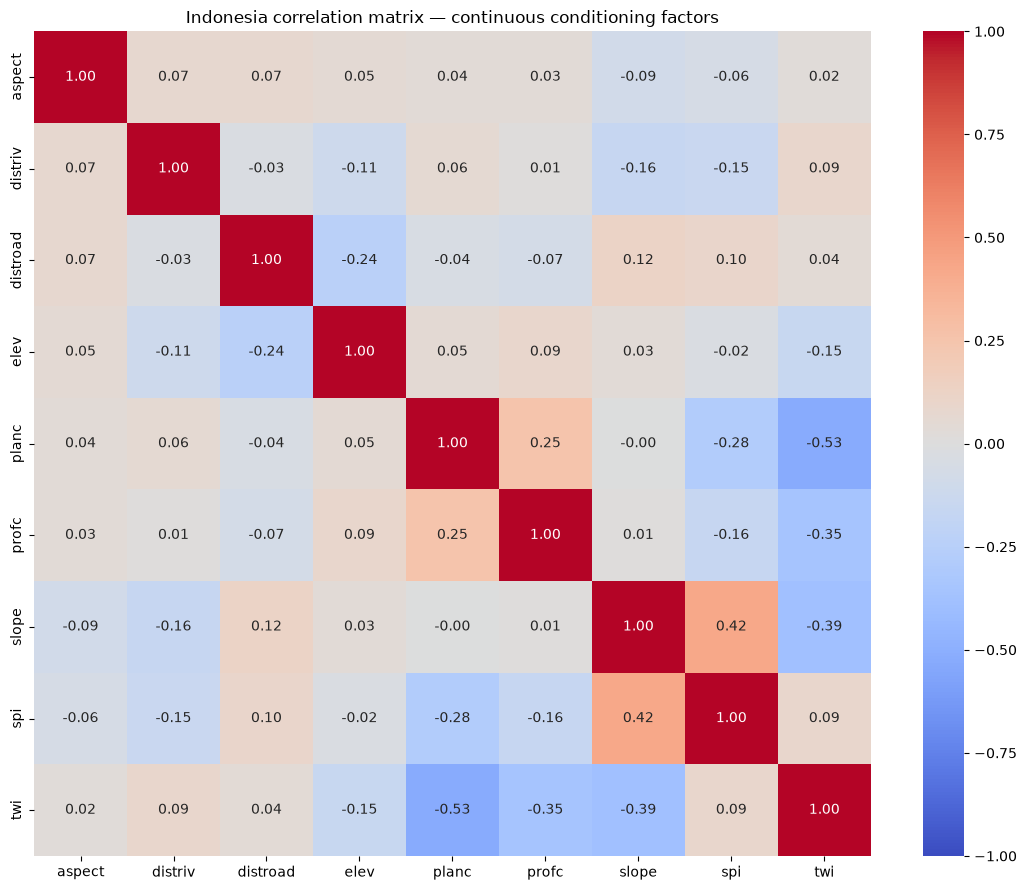

In [27]:
# 23 — Correlation matrix for all continuous dataset factors
# distriv and distroad are intentionally still included here.

corr = eda_df[continuous_factor_columns].corr()

plt.figure(figsize=(11, 9))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Indonesia correlation matrix — continuous conditioning factors")
plt.tight_layout()
plt.show()

In [28]:
# 24 — Variance Inflation Factor for all continuous dataset factors

vif_df = eda_df[continuous_factor_columns].dropna().copy()

if len(continuous_factor_columns) >= 2 and len(vif_df) > 0:
    vif_data = pd.DataFrame({
        "feature": continuous_factor_columns,
        "VIF": [
            variance_inflation_factor(vif_df.values, i)
            for i in range(len(continuous_factor_columns))
        ]
    })

    display(vif_data.sort_values("VIF", ascending=False))
else:
    print("Not enough continuous factors for VIF.")

,feature,VIF
8,twi,2.000323
6,slope,1.646119
4,planc,1.551892
7,spi,1.401995
5,profc,1.178620
3,elev,1.106503
2,distroad,1.100635
1,distriv,1.062241
0,aspect,1.028258


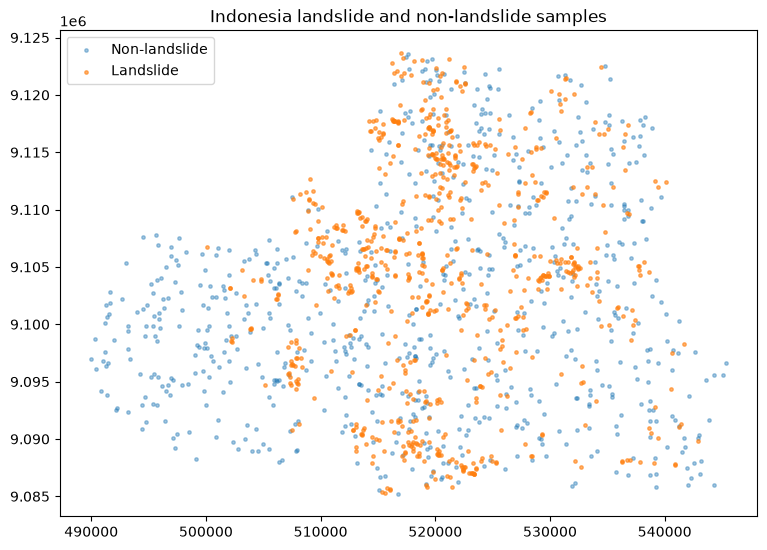

In [29]:
# 25 — Spatial distribution of supplied landslide and non-landslide samples

eda_gdf = gpd.GeoDataFrame(
    eda_df.copy(),
    geometry=gpd.GeoSeries.from_wkt(eda_df["geometry"]),
    crs=TARGET_CRS
)

fig, ax = plt.subplots(figsize=(9, 9))

eda_gdf[eda_gdf["label"] == 0].plot(
    ax=ax,
    markersize=6,
    alpha=0.40,
    label="Non-landslide"
)

eda_gdf[eda_gdf["label"] == 1].plot(
    ax=ax,
    markersize=6,
    alpha=0.60,
    label="Landslide"
)

ax.legend()
ax.set_title("Indonesia landslide and non-landslide samples")
plt.show()

## 8. Statistical relationship checks

In [30]:
# 26 — Mann–Whitney U test for continuous factors

mannwhitney_results = []

for col in continuous_factor_columns:
    group_0 = eda_df.loc[eda_df["label"] == 0, col].dropna()
    group_1 = eda_df.loc[eda_df["label"] == 1, col].dropna()

    if len(group_0) == 0 or len(group_1) == 0:
        continue

    u_stat, p_value = mannwhitneyu(
        group_0,
        group_1,
        alternative="two-sided"
    )

    n0 = len(group_0)
    n1 = len(group_1)

    rank_biserial = 1 - (2 * u_stat) / (n0 * n1)

    mannwhitney_results.append(
        {
            "Factor": col,
            "Non-landslide median": group_0.median(),
            "Landslide median": group_1.median(),
            "U statistic": u_stat,
            "p-value": p_value,
            "Rank-biserial": rank_biserial,
            "Significant": "Yes" if p_value < 0.05 else "No",
        }
    )

mannwhitney_df = pd.DataFrame(mannwhitney_results)
display(mannwhitney_df.round(4))

,Factor,Non-landslide median,Landslide median,U statistic,p-value,Rank-biserial,Significant
0,aspect,198.500,121.600,336407.0,0.0000,-0.2188,Yes
1,distriv,120.400,89.400,319823.0,0.0000,-0.1587,Yes
2,distroad,120.400,123.700,278655.5,0.7504,-0.0095,No
3,elev,363.900,405.200,257513.0,0.0252,0.0671,Yes
4,planc,0.001,-0.002,305874.5,0.0003,-0.1081,Yes
5,profc,0.000,-0.001,289214.0,0.1095,-0.0478,No
6,slope,15.200,22.200,176833.5,0.0000,0.3594,Yes
7,spi,0.338,0.732,193484.0,0.0000,0.2990,Yes
8,twi,5.300,5.160,299115.5,0.0052,-0.0837,Yes


In [31]:
# 27 — Interpret rank-biserial effect size

def interpret_rank_biserial(value):
    value = abs(value)

    if value < 0.10:
        return "Negligible"
    elif value < 0.30:
        return "Small"
    elif value < 0.50:
        return "Moderate"
    return "Large"

if not mannwhitney_df.empty:
    mannwhitney_df["Effect size"] = (
        mannwhitney_df["Rank-biserial"]
        .apply(interpret_rank_biserial)
    )

display(mannwhitney_df.round(4))

,Factor,Non-landslide median,Landslide median,U statistic,p-value,Rank-biserial,Significant,Effect size
0,aspect,198.500,121.600,336407.0,0.0000,-0.2188,Yes,Small
1,distriv,120.400,89.400,319823.0,0.0000,-0.1587,Yes,Small
2,distroad,120.400,123.700,278655.5,0.7504,-0.0095,No,Negligible
3,elev,363.900,405.200,257513.0,0.0252,0.0671,Yes,Negligible
4,planc,0.001,-0.002,305874.5,0.0003,-0.1081,Yes,Small
5,profc,0.000,-0.001,289214.0,0.1095,-0.0478,No,Negligible
6,slope,15.200,22.200,176833.5,0.0000,0.3594,Yes,Moderate
7,spi,0.338,0.732,193484.0,0.0000,0.2990,Yes,Small
8,twi,5.300,5.160,299115.5,0.0052,-0.0837,Yes,Negligible


In [32]:
# 28 — Chi-square test + Cramér's V for categorical factors

chi_square_results = []

for col in categorical_factor_columns:
    test_df = eda_df[[col, "label"]].dropna()

    contingency = pd.crosstab(
        test_df[col],
        test_df["label"]
    )

    if contingency.shape[0] < 2 or contingency.shape[1] < 2:
        print(f"Skipping {col}: contingency table is too small.")
        continue

    chi2, p_value, dof, expected = chi2_contingency(contingency)

    n = contingency.values.sum()
    rows, cols = contingency.shape
    denominator = n * min(rows - 1, cols - 1)

    cramers_v = (
        np.sqrt(chi2 / denominator)
        if denominator > 0
        else np.nan
    )

    chi_square_results.append(
        {
            "Factor": col,
            "Chi-square": chi2,
            "Degrees of freedom": dof,
            "p-value": p_value,
            "Cramer's V": cramers_v,
            "Significant": "Yes" if p_value < 0.05 else "No",
        }
    )

chi_square_df = pd.DataFrame(chi_square_results)
display(chi_square_df.round(4))

,Factor,Chi-square,Degrees of freedom,p-value,Cramer's V,Significant
0,geologi,122.1905,12,0.0,0.2869,Yes
1,landuse,43.6846,10,0.0,0.1715,Yes


In [33]:
# 29 — Interpret Cramér's V

def interpret_cramers_v(value):
    if pd.isna(value):
        return "Not available"
    if value < 0.10:
        return "Negligible"
    elif value < 0.30:
        return "Small"
    elif value < 0.50:
        return "Moderate"
    return "Large"

if not chi_square_df.empty:
    chi_square_df["Association strength"] = (
        chi_square_df["Cramer's V"]
        .apply(interpret_cramers_v)
    )

display(chi_square_df.round(4))

,Factor,Chi-square,Degrees of freedom,p-value,Cramer's V,Significant,Association strength
0,geologi,122.1905,12,0.0,0.2869,Yes,Small
1,landuse,43.6846,10,0.0,0.1715,Yes,Small


In [34]:
# 30 — Categorical contingency tables

for col in categorical_factor_columns:
    print(
        f"\n=============================="
        f"\n{col.upper()}"
        f"\n=============================="
    )

    table = pd.crosstab(
        eda_df[col],
        eda_df["label"],
        margins=True
    )

    display(table)


GEOLOGI


label,0,1,All
geologi,,,
2.0,32,18,50
7.0,141,233,374
8.0,165,52,217
12.0,6,4,10
13.0,2,2,4
16.0,20,24,44
20.0,21,16,37
26.0,71,43,114
27.0,29,22,51



LANDUSE


label,0,1,All
landuse,,,
1,1,0,1
2,5,2,7
3,174,211,385
4,7,6,13
5,22,7,29
6,132,134,266
8,90,79,169
10,70,22,92
11,92,106,198


## 9. Preprocessing for modelling

This is the stage where the two requested distance factors are removed.

The full saved Indonesia dataset still contains:

- `distriv`
- `distroad`

For modelling only, the feature list excludes them.

In [35]:
# 31 — Create modelling feature lists

model_continuous_factor_columns = [
    factor
    for factor in continuous_factor_columns
    if factor not in MODEL_EXCLUDE_FACTORS
]

model_categorical_factor_columns = (
    categorical_factor_columns.copy()
)

model_factor_columns = (
    model_continuous_factor_columns
    + model_categorical_factor_columns
)

print("Full dataset factors:")
print(dataset_factor_columns)

print("\nExcluded only from modelling:")
print(MODEL_EXCLUDE_FACTORS)

print("\nContinuous modelling factors:")
print(model_continuous_factor_columns)

print("\nCategorical modelling factors:")
print(model_categorical_factor_columns)

print("\nFinal modelling factors:")
print(model_factor_columns)

assert "distriv" in dataset_factor_columns
assert "distroad" in dataset_factor_columns
assert "distriv" not in model_factor_columns
assert "distroad" not in model_factor_columns

Full dataset factors:
['aspect', 'distriv', 'distroad', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']

Excluded only from modelling:
['distriv', 'distroad']

Continuous modelling factors:
['aspect', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi']

Categorical modelling factors:
['geologi', 'landuse']

Final modelling factors:
['aspect', 'elev', 'planc', 'profc', 'slope', 'spi', 'twi', 'geologi', 'landuse']


In [36]:
# 32 — Remove rows with missing selected modelling factors

model_df = eda_df[
    ["label"] + model_factor_columns
].copy()

print("Before dropna:", model_df.shape)

model_df = model_df.dropna(
    subset=model_factor_columns
)

print("After dropna :", model_df.shape)

print("\nClass balance:")
print(model_df["label"].value_counts())

Before dropna: (1486, 10)
After dropna : (1485, 10)

Class balance:
label
1    743
0    742
Name: count, dtype: int64


In [37]:
# 33 — Report potential continuous-factor outliers
# Do not silently remove them.

for col in model_continuous_factor_columns:
    q1, q3 = model_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    n_outliers = (
        (model_df[col] < lower) |
        (model_df[col] > upper)
    ).sum()

    print(
        f"{col:12s}: {n_outliers:,} potential outliers "
        "(IQR rule; reported only)"
    )

aspect      : 0 potential outliers (IQR rule; reported only)
elev        : 0 potential outliers (IQR rule; reported only)
planc       : 132 potential outliers (IQR rule; reported only)
profc       : 39 potential outliers (IQR rule; reported only)
slope       : 0 potential outliers (IQR rule; reported only)
spi         : 107 potential outliers (IQR rule; reported only)
twi         : 124 potential outliers (IQR rule; reported only)


In [38]:
# 34 — Stratified train/test split

from sklearn.model_selection import train_test_split

X = model_df[model_factor_columns]
y = model_df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Test :", X_test.shape, y_test.value_counts().to_dict())

print("\nDistance factors present in X_train?")
print("distriv :", "distriv" in X_train.columns)
print("distroad:", "distroad" in X_train.columns)

Train: (1188, 9) {1: 594, 0: 594}
Test : (297, 9) {1: 149, 0: 148}

Distance factors present in X_train?
distriv : False
distroad: False


In [39]:
# 35 — Fit preprocessing on TRAIN data only

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

transformers = []

if model_continuous_factor_columns:
    transformers.append(
        (
            "continuous",
            StandardScaler(),
            model_continuous_factor_columns
        )
    )

if model_categorical_factor_columns:
    transformers.append(
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            model_categorical_factor_columns
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("Processed train shape:", X_train_processed.shape)
print("Processed test shape :", X_test_processed.shape)

X_train_processed.head()

Processed train shape: (1188, 31)
Processed test shape : (297, 31)


,continuous__aspect,continuous__elev,continuous__planc,continuous__profc,continuous__slope,continuous__spi,continuous__twi,categorical__geologi_2.0,categorical__geologi_7.0,categorical__geologi_8.0,...,categorical__landuse_2,categorical__landuse_3,categorical__landuse_4,categorical__landuse_5,categorical__landuse_6,categorical__landuse_8,categorical__landuse_10,categorical__landuse_11,categorical__landuse_12,categorical__landuse_13
551,-0.731494,-0.771099,0.047449,0.405068,0.613001,0.864932,0.008627,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1453,1.275740,0.005138,1.597682,1.141254,-1.141807,-1.705932,-0.876453,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
870,1.731049,-0.266242,0.773090,0.159672,-1.318392,-0.450512,-0.644971,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1215,0.530777,2.355835,-0.282388,1.141254,-0.601017,-0.369124,0.131177,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
847,-1.058929,-1.311206,-0.183437,-0.576514,-0.910040,-0.323343,0.181104,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [40]:
# 36 — Save modelling-ready splits and fitted preprocessor

import joblib

X_train.to_csv(
    PROCESSED_DIR / "indonesia_X_train_raw.csv",
    index=False
)
X_test.to_csv(
    PROCESSED_DIR / "indonesia_X_test_raw.csv",
    index=False
)
y_train.to_csv(
    PROCESSED_DIR / "indonesia_y_train.csv",
    index=False
)
y_test.to_csv(
    PROCESSED_DIR / "indonesia_y_test.csv",
    index=False
)

X_train_processed.to_csv(
    PROCESSED_DIR / "indonesia_X_train_processed.csv",
    index=False
)

X_test_processed.to_csv(
    PROCESSED_DIR / "indonesia_X_test_processed.csv",
    index=False
)

joblib.dump(
    preprocessor,
    PROCESSED_DIR / "indonesia_preprocessor.pkl"
)

MODELLING_FACTORS_PATH = (
    PROCESSED_DIR /
    "indonesia_modelling_factor_list.json"
)

MODELLING_FACTORS_PATH.write_text(
    json.dumps(
        {
            "full_dataset_factors": dataset_factor_columns,
            "excluded_for_modelling": MODEL_EXCLUDE_FACTORS,
            "model_continuous_factors": model_continuous_factor_columns,
            "model_categorical_factors": model_categorical_factor_columns,
            "model_factors": model_factor_columns,
        },
        indent=2
    ),
    encoding="utf-8"
)

print("Saved Indonesia modelling-ready files to:")
print(PROCESSED_DIR)

print("\nConfirmed:")
print("- Full dataset keeps distriv and distroad.")
print("- Modelling inputs exclude distriv and distroad.")

Saved Indonesia modelling-ready files to:
D:\PROJECTS\Landslide_prediction\data\processed

Confirmed:
- Full dataset keeps distriv and distroad.
- Modelling inputs exclude distriv and distroad.


### Maps

In [41]:
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from shapely.geometry import box

In [42]:
def add_north_arrow(ax, x=0.95, y=0.95, arrow_length=0.08):
    ax.annotate(
        "N",
        xy=(x, y),
        xytext=(x, y - arrow_length),
        arrowprops=dict(facecolor="black", width=3, headwidth=10),
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        xycoords=ax.transAxes
    )

def add_scale_bar(ax, length=None, location=(0.08, 0.05), linewidth=3):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()

    if length is None:
        length = round((x1 - x0) / 5, -3)

    sbx = x0 + (x1 - x0) * location[0]
    sby = y0 + (y1 - y0) * location[1]

    ax.plot(
        [sbx, sbx + length],
        [sby, sby],
        color="black",
        linewidth=linewidth
    )

    ax.text(
        sbx + length / 2,
        sby + (y1 - y0) * 0.015,
        f"{int(length/1000)} km",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

In [43]:
# Use one raster to define study area extent
example_raster = factor_files[0]

with rasterio.open(example_raster) as src:
    bounds = src.bounds
    raster_crs = src.crs
    study_area_geom = box(bounds.left, bounds.bottom, bounds.right, bounds.top)

study_area = gpd.GeoDataFrame(
    {"name": ["Study Area"]},
    geometry=[study_area_geom],
    crs=raster_crs
)

# Reproject points to raster CRS if needed
landslides_map = landslides_raw.to_crs(raster_crs)
non_landslides_map = non_landslides_raw.to_crs(raster_crs)

study_area

,name,geometry
0,Study Area,"POLYGON ((546992.355 9084174.92, 546992.355 91..."


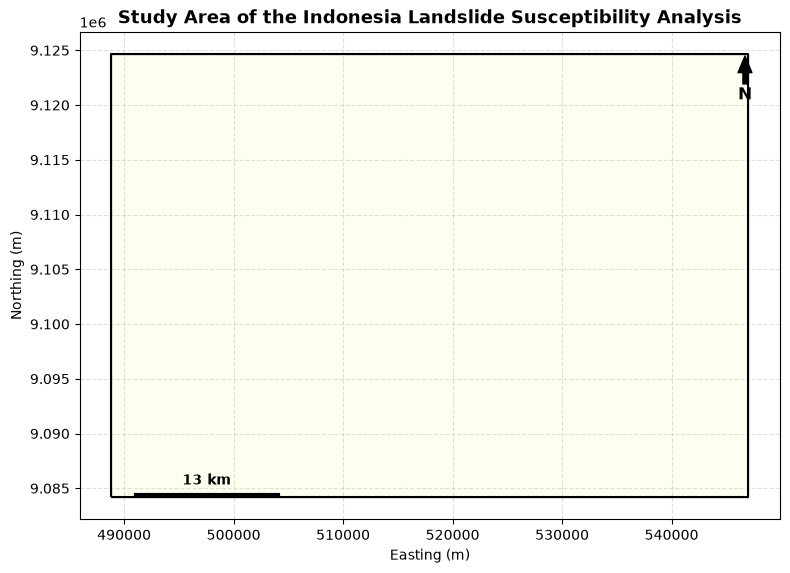

In [44]:
#Study area
fig, ax = plt.subplots(figsize=(8, 8))

study_area.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1.5
)

study_area.plot(
    ax=ax,
    color="lightyellow",
    edgecolor="black",
    alpha=0.5
)

ax.set_title("Study Area of the Indonesia Landslide Susceptibility Analysis", fontsize=13, fontweight="bold")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

add_north_arrow(ax)
add_scale_bar(ax)

ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "map_study_area_indonesia.png", dpi=300, bbox_inches="tight")
plt.show()

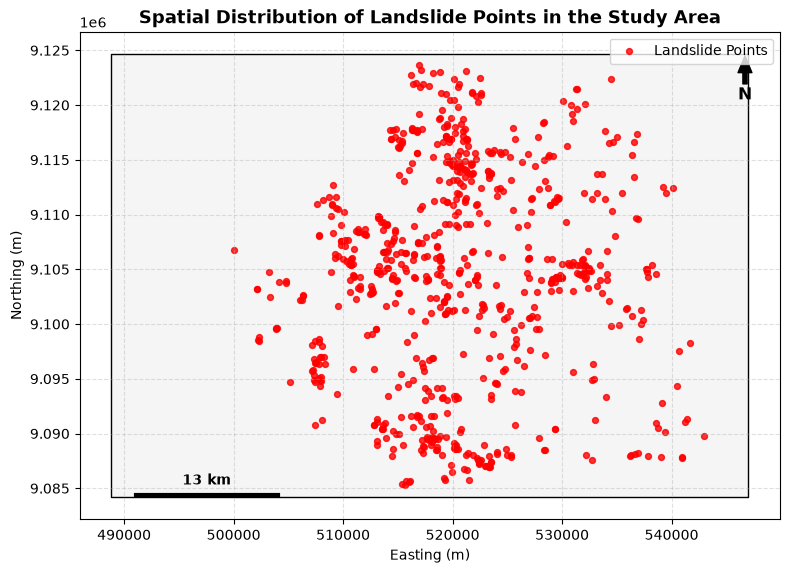

In [45]:
#Lanslide points
fig, ax = plt.subplots(figsize=(8, 8))

study_area.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=1
)

landslides_map.plot(
    ax=ax,
    color="red",
    markersize=18,
    alpha=0.8,
    label="Landslide Points"
)

ax.set_title("Spatial Distribution of Landslide Points in the Study Area", fontsize=13, fontweight="bold")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(loc="upper right")

add_north_arrow(ax)
add_scale_bar(ax)

ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "map_landslide_points_indonesia.png", dpi=300, bbox_inches="tight")
plt.show()

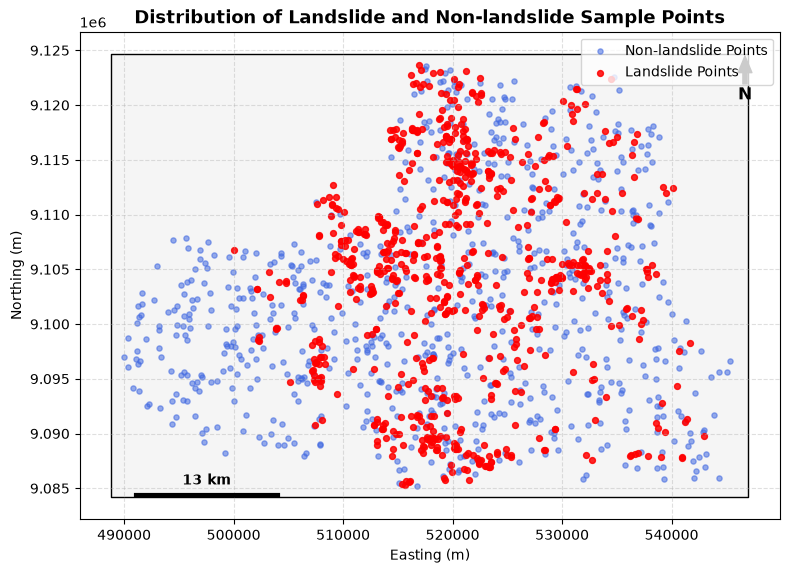

In [46]:
#Landslides and non-landslides points
fig, ax = plt.subplots(figsize=(8, 8))

study_area.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=1
)

non_landslides_map.plot(
    ax=ax,
    color="royalblue",
    markersize=14,
    alpha=0.55,
    label="Non-landslide Points"
)

landslides_map.plot(
    ax=ax,
    color="red",
    markersize=18,
    alpha=0.85,
    label="Landslide Points"
)

ax.set_title("Distribution of Landslide and Non-landslide Sample Points", fontsize=13, fontweight="bold")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(loc="upper right")

add_north_arrow(ax)
add_scale_bar(ax)

ax.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "map_landslide_nonlandslide_indonesia.png", dpi=300, bbox_inches="tight")
plt.show()

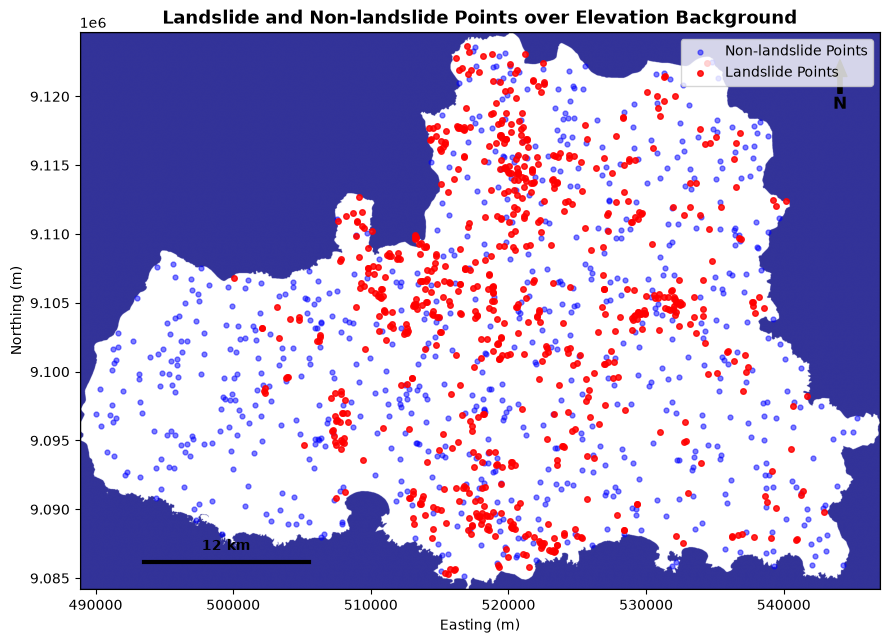

In [47]:
#Landslide and non-landslide points over elevation
elev_raster = FACTOR_DIR / "map_elev.tif"

with rasterio.open(elev_raster) as src:
    elev = src.read(1)
    elev_bounds = src.bounds

fig, ax = plt.subplots(figsize=(9, 8))

ax.imshow(
    elev,
    extent=[elev_bounds.left, elev_bounds.right, elev_bounds.bottom, elev_bounds.top],
    cmap="terrain",
    origin="upper"
)

study_area.boundary.plot(ax=ax, color="black", linewidth=1)

non_landslides_map.plot(
    ax=ax,
    color="blue",
    markersize=12,
    alpha=0.5,
    label="Non-landslide Points"
)

landslides_map.plot(
    ax=ax,
    color="red",
    markersize=16,
    alpha=0.85,
    label="Landslide Points"
)

ax.set_title("Landslide and Non-landslide Points over Elevation Background", fontsize=13, fontweight="bold")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.legend(loc="upper right")

add_north_arrow(ax)
add_scale_bar(ax)

plt.tight_layout()
plt.savefig(PROCESSED_DIR / "map_points_over_elevation_indonesia.png", dpi=300, bbox_inches="tight")
plt.show()

### Full Indonesia dataset
- `training_table_indonesia_extended.csv`
- `training_table_indonesia_extended.parquet`

These files **include `distriv` and `distroad`**.

### Preserved source inventories
- `indonesia_landslide_master.csv`
- `indonesia_landslide_master.gpkg`
- `indonesia_nonlandslide_master.csv`
- `indonesia_nonlandslide_master.gpkg`

### Reproducibility
- `indonesia_dataset_manifest.json`

### Modelling-ready data
- `indonesia_X_train_raw.csv`
- `indonesia_X_test_raw.csv`
- `indonesia_y_train.csv`
- `indonesia_y_test.csv`
- `indonesia_X_train_processed.csv`
- `indonesia_X_test_processed.csv`
- `indonesia_preprocessor.pkl`
- `indonesia_modelling_factor_list.json`

The modelling files exclude only `distriv` and `distroad`, as requested.